In [5]:
class GridWorld:
    def __init__(self, size=5, goal=(4, 4), obstacles=[(1, 1), (2, 2), (3, 3)]):
        self.size = size
        self.goal = goal
        self.obstacles = obstacles
        self.state = (0, 0)
        self.actions = [0, 1, 2, 3] # Up, Down, Left, Right

    def reset(self):
        self.state = (0, 0)
        return self.state

    def step(self, action):
        r, c = self.state
        if action == 0:    # Up
            next_state = (max(r - 1, 0), c)
        elif action == 1:  # Down
            next_state = (min(r + 1, self.size - 1), c)
        elif action == 2:  # Left
            next_state = (r, max(c - 1, 0))
        elif action == 3:  # Right
            next_state = (r, min(c + 1, self.size - 1))

        if next_state in self.obstacles:
            # Penalty for hitting obstacle, bounce back
            return self.state, -10.0, False

        self.state = next_state
        if self.state == self.goal:
            return self.state, 10.0, True

        return self.state, -1.0, False

In [6]:
def q_learning(env, episodes=200, alpha=0.1, gamma=0.99, epsilon=0.1, decay=False):
    # Initialize Q-table: State (r, c) -> Action values
    q_table = {}
    for r in range(env.size):
        for c in range(env.size):
            q_table[(r, c)] = [0.0] * len(env.actions)

    rewards_per_episode = []
    steps_per_episode = []
    curr_epsilon = epsilon

    for ep in range(episodes):
        state = env.reset()
        total_reward = 0
        steps = 0
        done = False

        if decay:
            curr_epsilon = max(0.01, epsilon * (0.98 ** ep))

        while not done and steps < 100:
            # Epsilon-greedy action selection
            if random.random() < curr_epsilon:
                action = random.choice(env.actions)
            else:
                action = np.argmax(q_table[state])

            next_state, reward, done = env.step(action)

            # Q-update
            best_next = np.max(q_table[next_state])
            q_table[state][action] += alpha * (reward + gamma * best_next - q_table[state][action])

            state = next_state
            total_reward += reward
            steps += 1

        rewards_per_episode.append(total_reward)
        steps_per_episode.append(steps)

    return rewards_per_episode, steps_per_episode, q_table

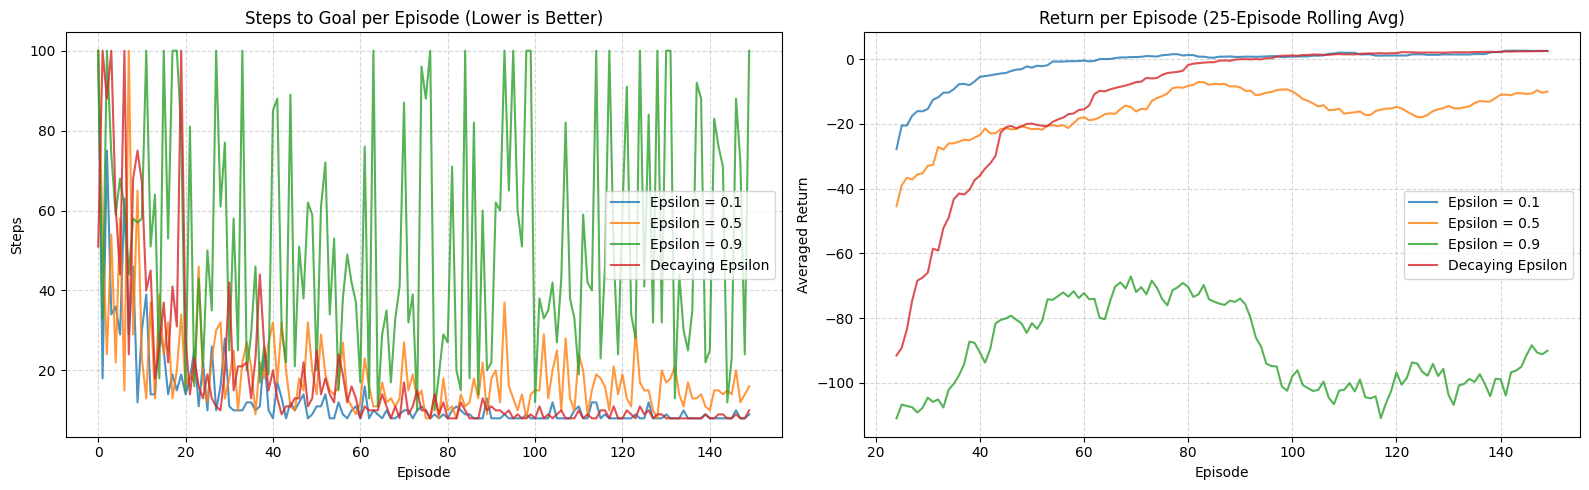

In [9]:
env = GridWorld()
episodes = 150

# Run experiments for different exploration rates
epsilons = [0.1, 0.5, 0.9]
results = {}

for eps in epsilons:
    rewards, steps, _ = q_learning(env, episodes=episodes, epsilon=eps, decay=False)
    results[f'Epsilon = {eps}'] = (rewards, steps)

# Run decaying epsilon (best practice)
rewards_dec, steps_dec, _ = q_learning(env, episodes=episodes, epsilon=1.0, decay=True)
results['Decaying Epsilon'] = (rewards_dec, steps_dec)

# Visualization (Figure 6.1 style)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot Steps per Episode (Convergence Speed)
for label, (rewards, steps) in results.items():
    axes[0].plot(steps, label=label, alpha=0.8)
axes[0].set_title('Steps to Goal per Episode (Lower is Better)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Steps')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot Rolling Average Reward (25-episode window matching Figure 6.1)
for label, (rewards, steps) in results.items():
    # Use 25-episode sliding window for averaging
    window_size = 25
    rolling_reward = np.convolve(rewards, np.ones(window_size)/window_size, mode='valid')
    axes[1].plot(range(window_size - 1, len(rewards)), rolling_reward, label=label, alpha=0.8)
axes[1].set_title('Return per Episode (25-Episode Rolling Avg)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Averaged Return')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

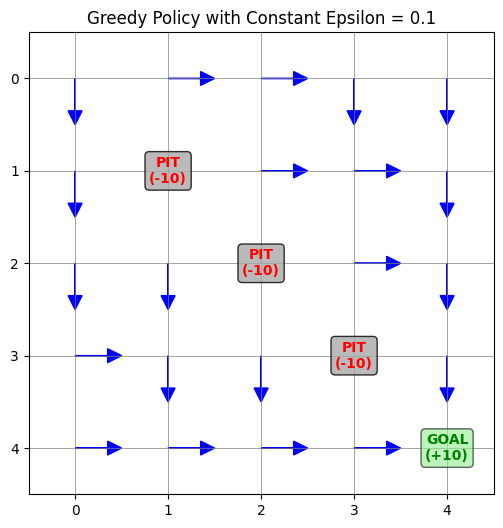

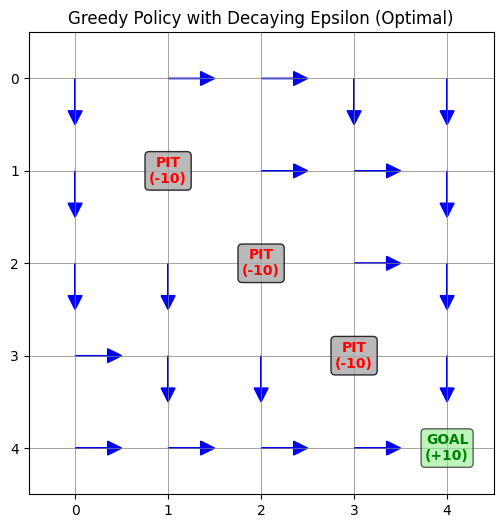

In [8]:
def plot_policy(q_table, env, title):
    grid_size = env.size
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_xlim(-0.5, grid_size - 0.5)
    ax.set_ylim(grid_size - 0.5, -0.5) # Invert y-axis to match array indexing
    ax.set_xticks(np.arange(grid_size))
    ax.set_yticks(np.arange(grid_size))
    ax.grid(True, color='gray', linestyle='-', linewidth=0.5)

    # Action maps for plotting
    # Actions: 0: Up (0, -1), 1: Down (0, 1), 2: Left (-1, 0), 3: Right (1, 0)
    action_vectors = {
        0: (0, -0.35),
        1: (0, 0.35),
        2: (-0.35, 0),
        3: (0.35, 0)
    }

    for r in range(grid_size):
        for c in range(grid_size):
            state = (r, c)
            if state == env.goal:
                ax.text(c, r, 'GOAL\n(+10)', ha='center', va='center', color='green', weight='bold', bbox=dict(facecolor='lightgreen', alpha=0.6, boxstyle='round'))
            elif state in env.obstacles:
                ax.text(c, r, 'PIT\n(-10)', ha='center', va='center', color='red', weight='bold', bbox=dict(facecolor='darkgray', alpha=0.8, boxstyle='round'))
            else:
                # Draw greedy action arrow
                best_action = np.argmax(q_table[state])
                dx, dy = action_vectors[best_action]
                ax.arrow(c, r, dx, dy, head_width=0.15, head_length=0.15, fc='blue', ec='blue')

    ax.set_title(title)
    plt.show()

# Retrain models to extract policies
_, _, q_01 = q_learning(env, episodes=episodes, epsilon=0.1, decay=False)
_, _, q_decay = q_learning(env, episodes=episodes, epsilon=1.0, decay=True)

# Plot greedy policies
plot_policy(q_01, env, "Greedy Policy with Constant Epsilon = 0.1")
plot_policy(q_decay, env, "Greedy Policy with Decaying Epsilon (Optimal)")